# 01 — Dataset Comparison & Cross-Network Zeek Audit

Datasets compared in this notebook:
1. **CIC-IDS2017** (UNB CIC — converted to Zeek)
2. **UWF-ZeekData** (University of West Florida — 2024 & 2025)
3. **AIT-LDSv2** (Austrian Institute of Technology — 2022 `russellmitchell`, converted to Zeek)
4. **TON_IoT** (UNSW Canberra — Network CSV)
5. **UNSW-NB15** (UNSW Canberra — converted to Zeek)

**Goal:** Compare all five side-by-side, inspect host-behavior differences, and test our production `zeek-hybrid-m3-v1` model across every Zeek test set.

## 1. How realistic is each dataset's benign & host traffic?
We check benign TCP payload bytes (to catch idle labs) and 60-second per-host burst rates (to catch synthetic traffic generators).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

from cybershield.ml.zeek_features import (
    ZEEK_HYBRID_FEATURES,
    load_ait_zeek,
    load_cic2017_zeek,
    load_ton_iot,
    load_unsw_zeek,
    load_uwf_zeek,
)
from cybershield.ml.train_zeek import MODELS_DIR, evaluate_predictions


def summarize(name: str, df: pd.DataFrame, has_ts: bool = True) -> dict:
    btcp = df[(df["label"] == 0) & (df["proto"] == "tcp")]
    row = {
        "Dataset": name,
        "Flows": len(df),
        "Attack %": round(df["label"].mean() * 100, 1),
        "Benign TCP": len(btcp),
        "Benign TCP Med Bytes": round(float((btcp["orig_bytes"].fillna(0) + btcp["resp_bytes"].fillna(0)).median()), 1) if len(btcp) else 0.0,
        "Has ts?": "Yes" if has_ts else "No",
    }
    if has_ts:
        row["Benign Med conn/60s"] = round(float(df.loc[df["label"] == 0, "host_conn_60s"].median()), 1)
        row["Attack Med conn/60s"] = round(float(df.loc[df["label"] == 1, "host_conn_60s"].median()), 1)
        row["Benign Med ports/60s"] = round(float(df.loc[df["label"] == 0, "host_uniq_ports_60s"].median()), 1)
        row["Attack Med ports/60s"] = round(float(df.loc[df["label"] == 1, "host_uniq_ports_60s"].median()), 1)
    else:
        for k in ["Benign Med conn/60s", "Attack Med conn/60s", "Benign Med ports/60s", "Attack Med ports/60s"]:
            row[k] = np.nan
    return row


cic = load_cic2017_zeek()
uwf24 = load_uwf_zeek("UWF-ZeekData24")
uwf_f24 = load_uwf_zeek("UWF-ZeekDataFall24-2")
uwf_s25_1 = load_uwf_zeek("UWF-ZeekDataSum25-1")
uwf_s25_2 = load_uwf_zeek("UWF-ZeekDataSum25-2")
ton = load_ton_iot()
ait_z = load_ait_zeek()
unsw_z = load_unsw_zeek()

comp_df = pd.DataFrame([
    summarize("CIC-IDS2017 (5d Zeek)", cic),
    summarize("UWF-ZeekData24", uwf24),
    summarize("UWF-ZeekDataFall24-2", uwf_f24),
    summarize("UWF-ZeekDataSum25-1", uwf_s25_1),
    summarize("UWF-ZeekDataSum25-2", uwf_s25_2),
    summarize("AIT-LDSv2 (2022 Zeek)", ait_z),
    summarize("TON_IoT (CSV)", ton, has_ts=False),
    summarize("UNSW-NB15 (20GB Zeek)", unsw_z),
])
display(comp_df)

,Dataset,Flows,Attack %,Benign TCP,Benign TCP Med Bytes,Has ts?,Benign Med conn/60s,Attack Med conn/60s,Benign Med ports/60s,Attack Med ports/60s
0,CIC-IDS2017 (5d Zeek),2109238,21.8,612481,4077.0,Yes,276.0,8375.0,4.0,1.0
1,UWF-ZeekData24,1898613,49.5,67447,0.0,Yes,26.0,210.0,1.0,1.0
2,UWF-ZeekDataFall24-2,2901532,49.8,109789,0.0,Yes,4.0,85840.0,1.0,39961.0
3,UWF-ZeekDataSum25-1,1149977,49.8,68,10615.0,Yes,3.0,5959.0,1.0,3.0
4,UWF-ZeekDataSum25-2,1868679,50.0,2048,177636.0,Yes,8.0,56522.0,1.0,22140.0
5,AIT-LDSv2 (2022 Zeek),254947,90.6,22,2326.5,Yes,3.0,5870.0,1.0,2.0
6,TON_IoT (CSV),211043,76.3,18203,0.0,No,NaN,NaN,NaN,NaN
7,UNSW-NB15 (20GB Zeek),393113,1.1,281340,5266.0,Yes,134.0,32.0,58.0,8.0


## 2. Visual check: Normal vs. Attack host burst behavior
Notice how `UNSW-NB15`'s 2015 IXIA Normal traffic is **inverted** (134 conn/min & 58 ports/min for Normal vs. only 32 conn/min & 8 ports/min for Attacks).

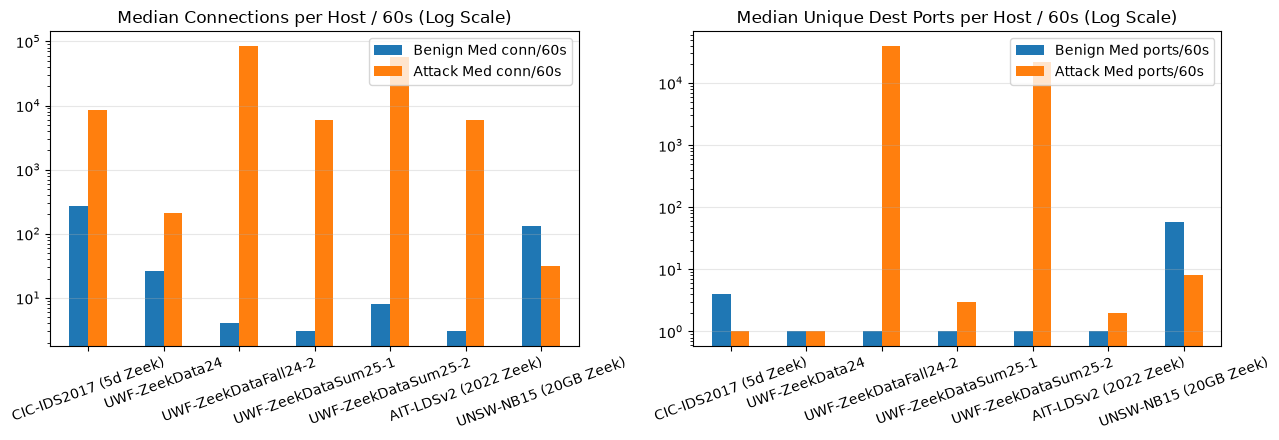

In [2]:
plot_df = comp_df.dropna(subset=["Benign Med conn/60s"]).set_index("Dataset")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_df[["Benign Med conn/60s", "Attack Med conn/60s"]].plot(kind="bar", ax=axes[0], rot=20)
axes[0].set_title("Median Connections per Host / 60s (Log Scale)")
axes[0].set_yscale("log")
axes[0].set_xlabel("")
axes[0].grid(axis="y", alpha=0.3)

plot_df[["Benign Med ports/60s", "Attack Med ports/60s"]].plot(kind="bar", ax=axes[1], rot=20)
axes[1].set_title("Median Unique Dest Ports per Host / 60s (Log Scale)")
axes[1].set_yscale("log")
axes[1].set_xlabel("")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Production model (`zeek-hybrid-m3-v1`) evaluated across all 4 Zeek test sets
Loads the trained model from `models/zeek-hybrid-m3-v1.joblib` (trained by `python -m cybershield.ml.train_zeek`).

In [3]:
from sklearn.model_selection import StratifiedGroupKFold

model = joblib.load(MODELS_DIR / "zeek-hybrid-m3-v1.joblib")
groups = cic["source"].astype(str) + "_" + cic["src_ip"].astype(str) + "_" + cic["window_id"].astype(str)
_, te_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(cic, cic["label"], groups))

tests = {
    "CIC-IDS2017 (held-out)": cic.iloc[te_idx],
    "UWF-Sum25-1 (unseen 2025)": uwf_s25_1,
    "UWF-Sum25-2 (unseen 2025)": uwf_s25_2,
    "AIT-LDSv2 (2022 Zeek, zero-shot)": ait_z,
    "UNSW-NB15 (20GB Zeek, zero-shot)": unsw_z,
}

rows = []
for name, tdf in tests.items():
    probs = model.predict_proba(tdf[ZEEK_HYBRID_FEATURES])[:, 1]
    m = evaluate_predictions(tdf["label"].to_numpy(dtype=int), probs)
    rows.append({"Test Set": name, "Flows": len(tdf), "ROC-AUC": m["roc_auc"], "F1": m["f1"], "Recall": m["recall"], "FPR": m["false_positive_rate"]})
display(pd.DataFrame(rows))

,Test Set,Flows,ROC-AUC,F1,Recall,FPR
0,CIC-IDS2017 (held-out),421847,0.9999,0.9943,0.9994,0.00305
1,UWF-Sum25-1 (unseen 2025),1149977,0.9999,0.8865,0.7961,0.00001
2,UWF-Sum25-2 (unseen 2025),1868679,0.9998,0.9991,0.9987,0.00056
3,"AIT-LDSv2 (2022 Zeek, zero-shot)",254947,0.9990,0.9850,0.9704,0.00013
4,"UNSW-NB15 (20GB Zeek, zero-shot)",393113,0.4106,0.0086,0.0361,0.08496


## 4. Dataset Sources, Pros, Cons & Verdict

| Dataset | Source | Role | Pros | Cons / Flaws | Key Notes |
|---|---|---|---|---|---|
| **CIC-IDS2017** *(5d Zeek)* | [UNB](https://www.unb.ca/cic/datasets/ids-2017.html) · [HF](https://huggingface.co/datasets/bvsam/cic-ids-2017) | **Primary train & test** | Real Zeek `conn.log` schema; **612k real benign TCP** (SSL/HTTP/SSH/FTP, med 4 KB); timestamps for 60s windows; benign & 12+ attacks on same LAN. | Single lab (attacker hit 1 IP → dropped `host_uniq_ips_60s`); 2017 traffic; Thu Web Attacks mostly empty/failed flows. | 52 GB PCAPs → 48 MB Parquet on Colab; relabeled from UNB GT schedule (`99.87%` binary match, restored `DoS GoldenEye` & Friday `Bot`). |
| **UWF-ZeekData24 & Fall24-2** | [UWF](https://datasets.uwf.edu/data/) | **Co-training (attacks)** | Native Zeek Parquet; modern 2024 captures; MITRE ATT&CK labels (Credential Access, Discovery, Recon, Defense Evasion, Lateral Movement, Exfil). | **Idle-lab benign** (92–99% UDP DNS, **0-byte** TCP); benign & attack in separate weeks. | Pair balanced chunks with `CIC-IDS2017` for MITRE diversity. Drop `label_binary == "Duplicate"` rows. |
| **UWF-Sum25-1 & Sum25-2** | [UWF](https://datasets.uwf.edu/data/) | **Unseen 2025 test** | Newer (Summer 2025); tests temporal generalization (`2024 → 2025`). | Same idle-lab benign quirk; `Sum25-2` has only 2 tactics & 32 attack host-minutes. | Proves temporal generalization (`0.887–0.999` F1, `≤0.056%` FPR for `M3`). |
| **AIT-LDSv2** *(2022 Zeek)* | [Zenodo](https://zenodo.org/records/5789064) | **Unseen 3rd-network test** | Real 2022 multi-step red-team chain (OpenVPN internal sweep, WP-Crack, reverse shell, dnsteal); exact attacker IPs in config. | PCAPs in `russellmitchell.zip` were captured on `attacker_0` (~91% attacker flows). | 7.1 GB zip → 6.7 MB Parquet; `M3` got **0.00% FPR** on normal hosts & **72–98%** recall on attacker IPs zero-shot! |
| **TON_IoT** *(CSV)* | [UNSW](https://research.unsw.edu.au/projects/toniot-datasets) · [HF](https://huggingface.co/datasets/codymlewis/TON_IoT_network) | **Single-flow ref** | Native Zeek columns; real benign TCP + 9 attack types. | **No `ts` timestamps** (no 60s windows); IoT sensor loop (`src_pkts == 120`); 56% duplicates. | Useful single-flow zero-shot check (AUC `0.724`), incompatible with Hybrid 60s context. |
| **UNSW-NB15** *(20 GB Zeek)* | [UNSW](https://research.unsw.edu.au/projects/unsw-nb15-dataset) · [PCAP](https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15) · [GT](https://huggingface.co/datasets/Mouwiya/UNSW-NB15) | **Excluded (audit)** | Classic 9-class benchmark; 281k benign TCP flows with real payloads. | **Inverted 2015 IXIA Normal:** 10 Normal IPs blast **134 conn/min & 58 ports/min** vs. **32 & 8** for attacks (AUC `0.41`). Legacy CSV uses Argus & TTL. | Real-world takeaway: **allowlist NAT gateways/proxies** (`allowlist_src_ips` in `score_zeek_flows()`). |